# Catalyst inventory and catalyst flow rate

Comparison of the three catalysts (Ni, Fe and activated carbon, AC) at their selected operating temperatures for the 100 TPD H$_2$ plant:

1. **Catalyst inventory**: the amount of catalyst held in the reactor.
2. **Catalyst flow rate**: the circulation rate of catalyst through the reactor, for a CSTR and a PFR.

The flow rates are read straight from the simulation results in `<catalyst>MP/Results_Simulations/`, so the figure stays in sync with the simulations.

## Setup

In [21]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scienceplots  # noqa: F401  (registers the "science" styles)
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator

plt.style.use(["science", "ieee"])

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

## Catalyst cases

One entry per catalyst. `inventory` is the catalyst amount in the reactor [kg]; together with the temperature it identifies the simulation file to read.

In [22]:
PROJECT_ROOT = Path("..")

CATALYSTS = {
    "Ni": {"temperature": 600, "inventory":    950, "color": "#E69F00", "folder": "NiMP"},
    "Fe": {"temperature": 725, "inventory": 10_000, "color": "#7B4AB5", "folder": "FeMP"},
    "AC": {"temperature": 825, "inventory": 210_000, "color": "#D62728", "folder": "ACMP"},
}

REACTORS = ["CSTR", "PFR"]


def simulation_file(catalyst, reactor):
    """Path to the simulation result for a catalyst case and reactor type."""
    case = CATALYSTS[catalyst]
    name = (f"sim-{reactor}-100TPD-ch4-t{case['temperature']}-p1.07"
            f"-c{case['inventory']}-da0.2-psa15.csv")
    return PROJECT_ROOT / case["folder"] / "Results_Simulations" / name


names = list(CATALYSTS)
colors = [CATALYSTS[c]["color"] for c in names]
x_labels = [f"{c}\n{CATALYSTS[c]['temperature']} $^\\circ$C" for c in names]

inventory = np.array([CATALYSTS[c]["inventory"] for c in names], dtype=float)

# Catalyst flow rate [kg/h], indexed by catalyst, one column per reactor
flow_rate = pd.DataFrame({
    reactor: [pd.read_csv(simulation_file(c, reactor))["Cat Rate [kg/h]"].iloc[0] for c in names]
    for reactor in REACTORS
}, index=names)

flow_rate.round(1)

,CSTR,PFR
Ni,101.4,58.6
Fe,8594.6,7897.3
AC,70490.8,61838.3


## Plot helpers

Both figures use a log-scaled y-axis with bars that start at the bottom of the axis (`y_min`), so bars are drawn from `y_min` up to the value.

In [23]:
def thousands(value, _position=None):
    """Format a number with thousands separators and no decimals, e.g. 10,000."""
    return f"{value:,.0f}"


def style_log_axis(ax, y_min, y_max, major_length, minor_length, major_width, minor_width,
                   spine_width, label_size, pad):
    """Log y-axis with labelled decades, unlabelled minor ticks, inward ticks on all sides."""
    ax.set_yscale("log")
    ax.set_ylim(y_min, y_max)

    ax.yaxis.set_major_locator(LogLocator(base=10, numticks=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_major_formatter(FuncFormatter(thousands))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda value, position: ""))

    ax.tick_params(axis="both", which="major", direction="in", top=True, right=True,
                   length=major_length, width=major_width, labelsize=label_size, pad=pad)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True,
                   length=minor_length, width=minor_width)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(spine_width)


def annotate_bars(ax, bars, values, offset_factors, fontsize, fmt):
    """Write each bar's value just above it (offset is multiplicative because of the log axis)."""
    for bar, value, factor in zip(bars, values, offset_factors):
        ax.text(bar.get_x() + bar.get_width() / 2, value * factor, fmt(value),
                ha="center", va="bottom", fontsize=fontsize, color="black")

## Figure 1: Catalyst inventory

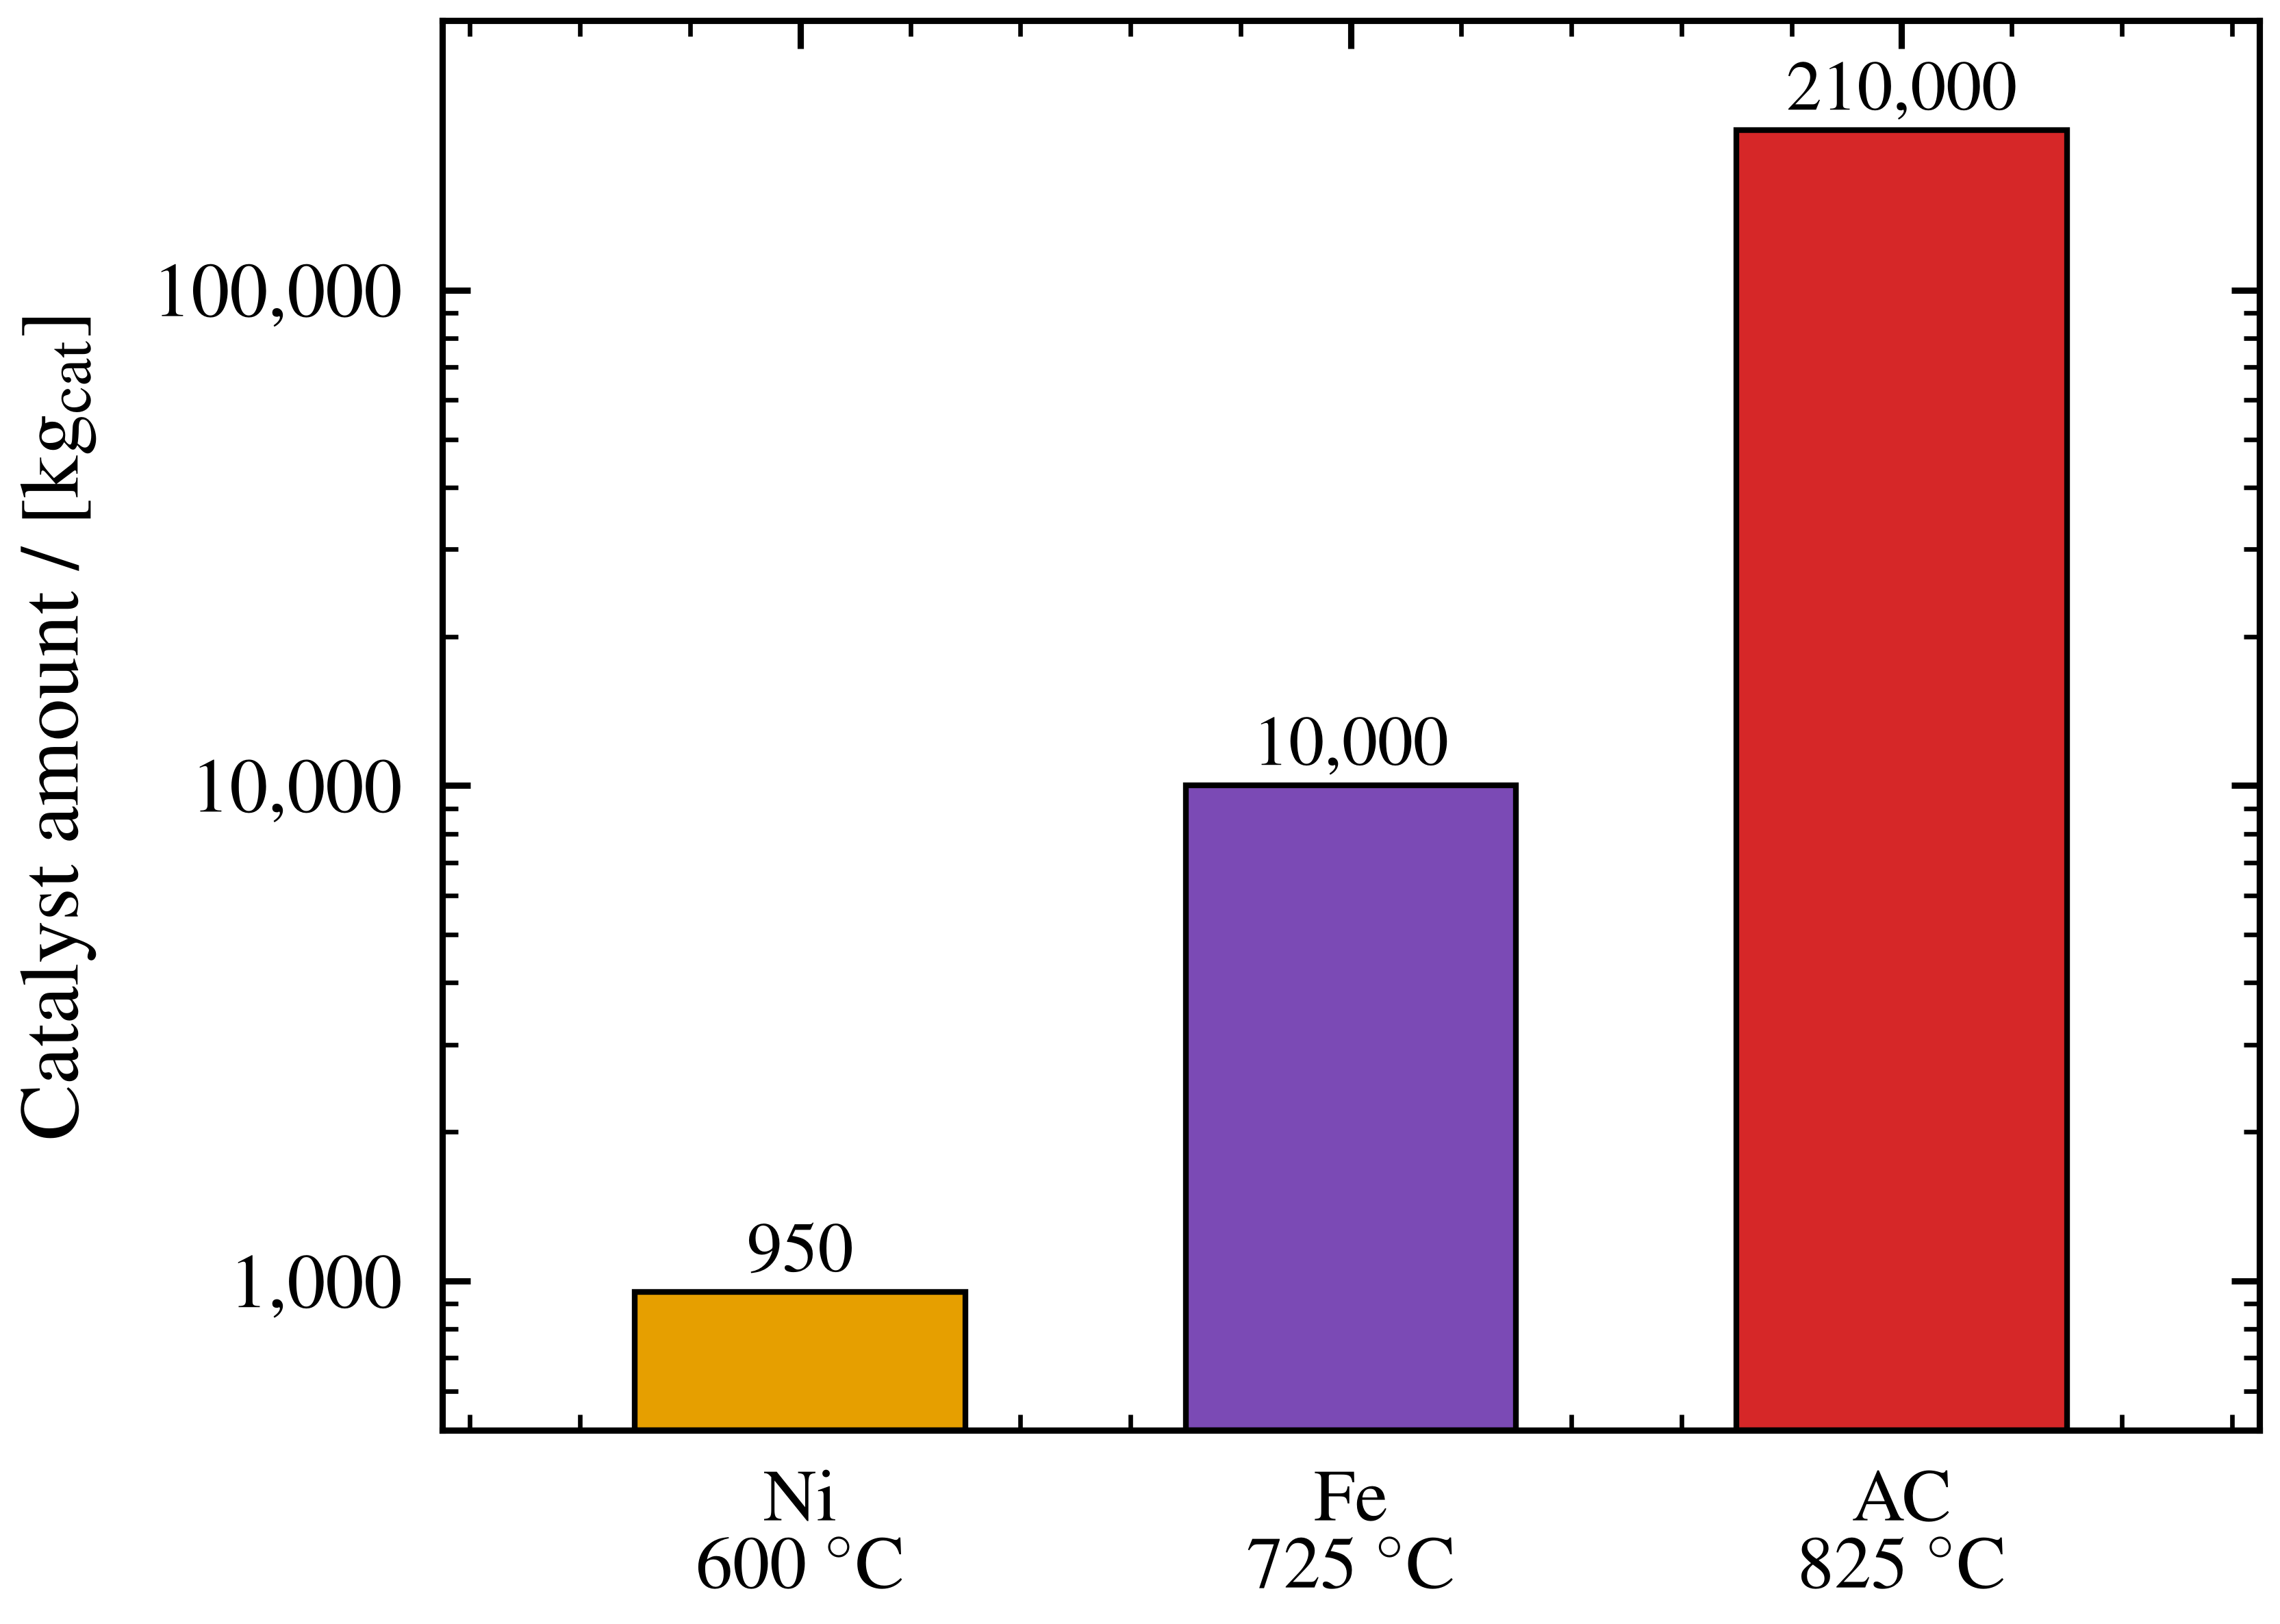

In [24]:
TICK_FONT = 13.5
XLABEL_FONT = 13.0
AXIS_LABEL_FONT = 14.8
VALUE_FONT = 12.5

y_min, y_max = 500, 350_000

fig, ax = plt.subplots(figsize=(5.6, 4.4))
x = np.arange(len(names))

bars = ax.bar(x, inventory - y_min, bottom=y_min, width=0.60,
              color=colors, edgecolor="black", linewidth=1.0, zorder=2)

style_log_axis(ax, y_min, y_max, major_length=4.9, minor_length=2.8, major_width=1.1,
               minor_width=0.8, spine_width=1.1, label_size=TICK_FONT, pad=7)
annotate_bars(ax, bars, inventory, offset_factors=[1.025] * len(names),
              fontsize=VALUE_FONT, fmt=thousands)

ax.set_ylabel(r"Catalyst amount / [kg$_{\mathrm{cat}}$]", fontsize=AXIS_LABEL_FONT, labelpad=10)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=XLABEL_FONT)
ax.set_xlim(-0.65, len(names) - 0.35)

fig.subplots_adjust(left=0.18, right=0.97, bottom=0.18, top=0.96)
fig.savefig("catalyst_amount_comparison.pdf", format="pdf")
plt.show()

## Figure 2: Catalyst flow rate, CSTR vs PFR

CSTR bars are solid, PFR bars are hatched. The value labels are nudged up by a per-bar factor so neighbouring labels don't overlap.

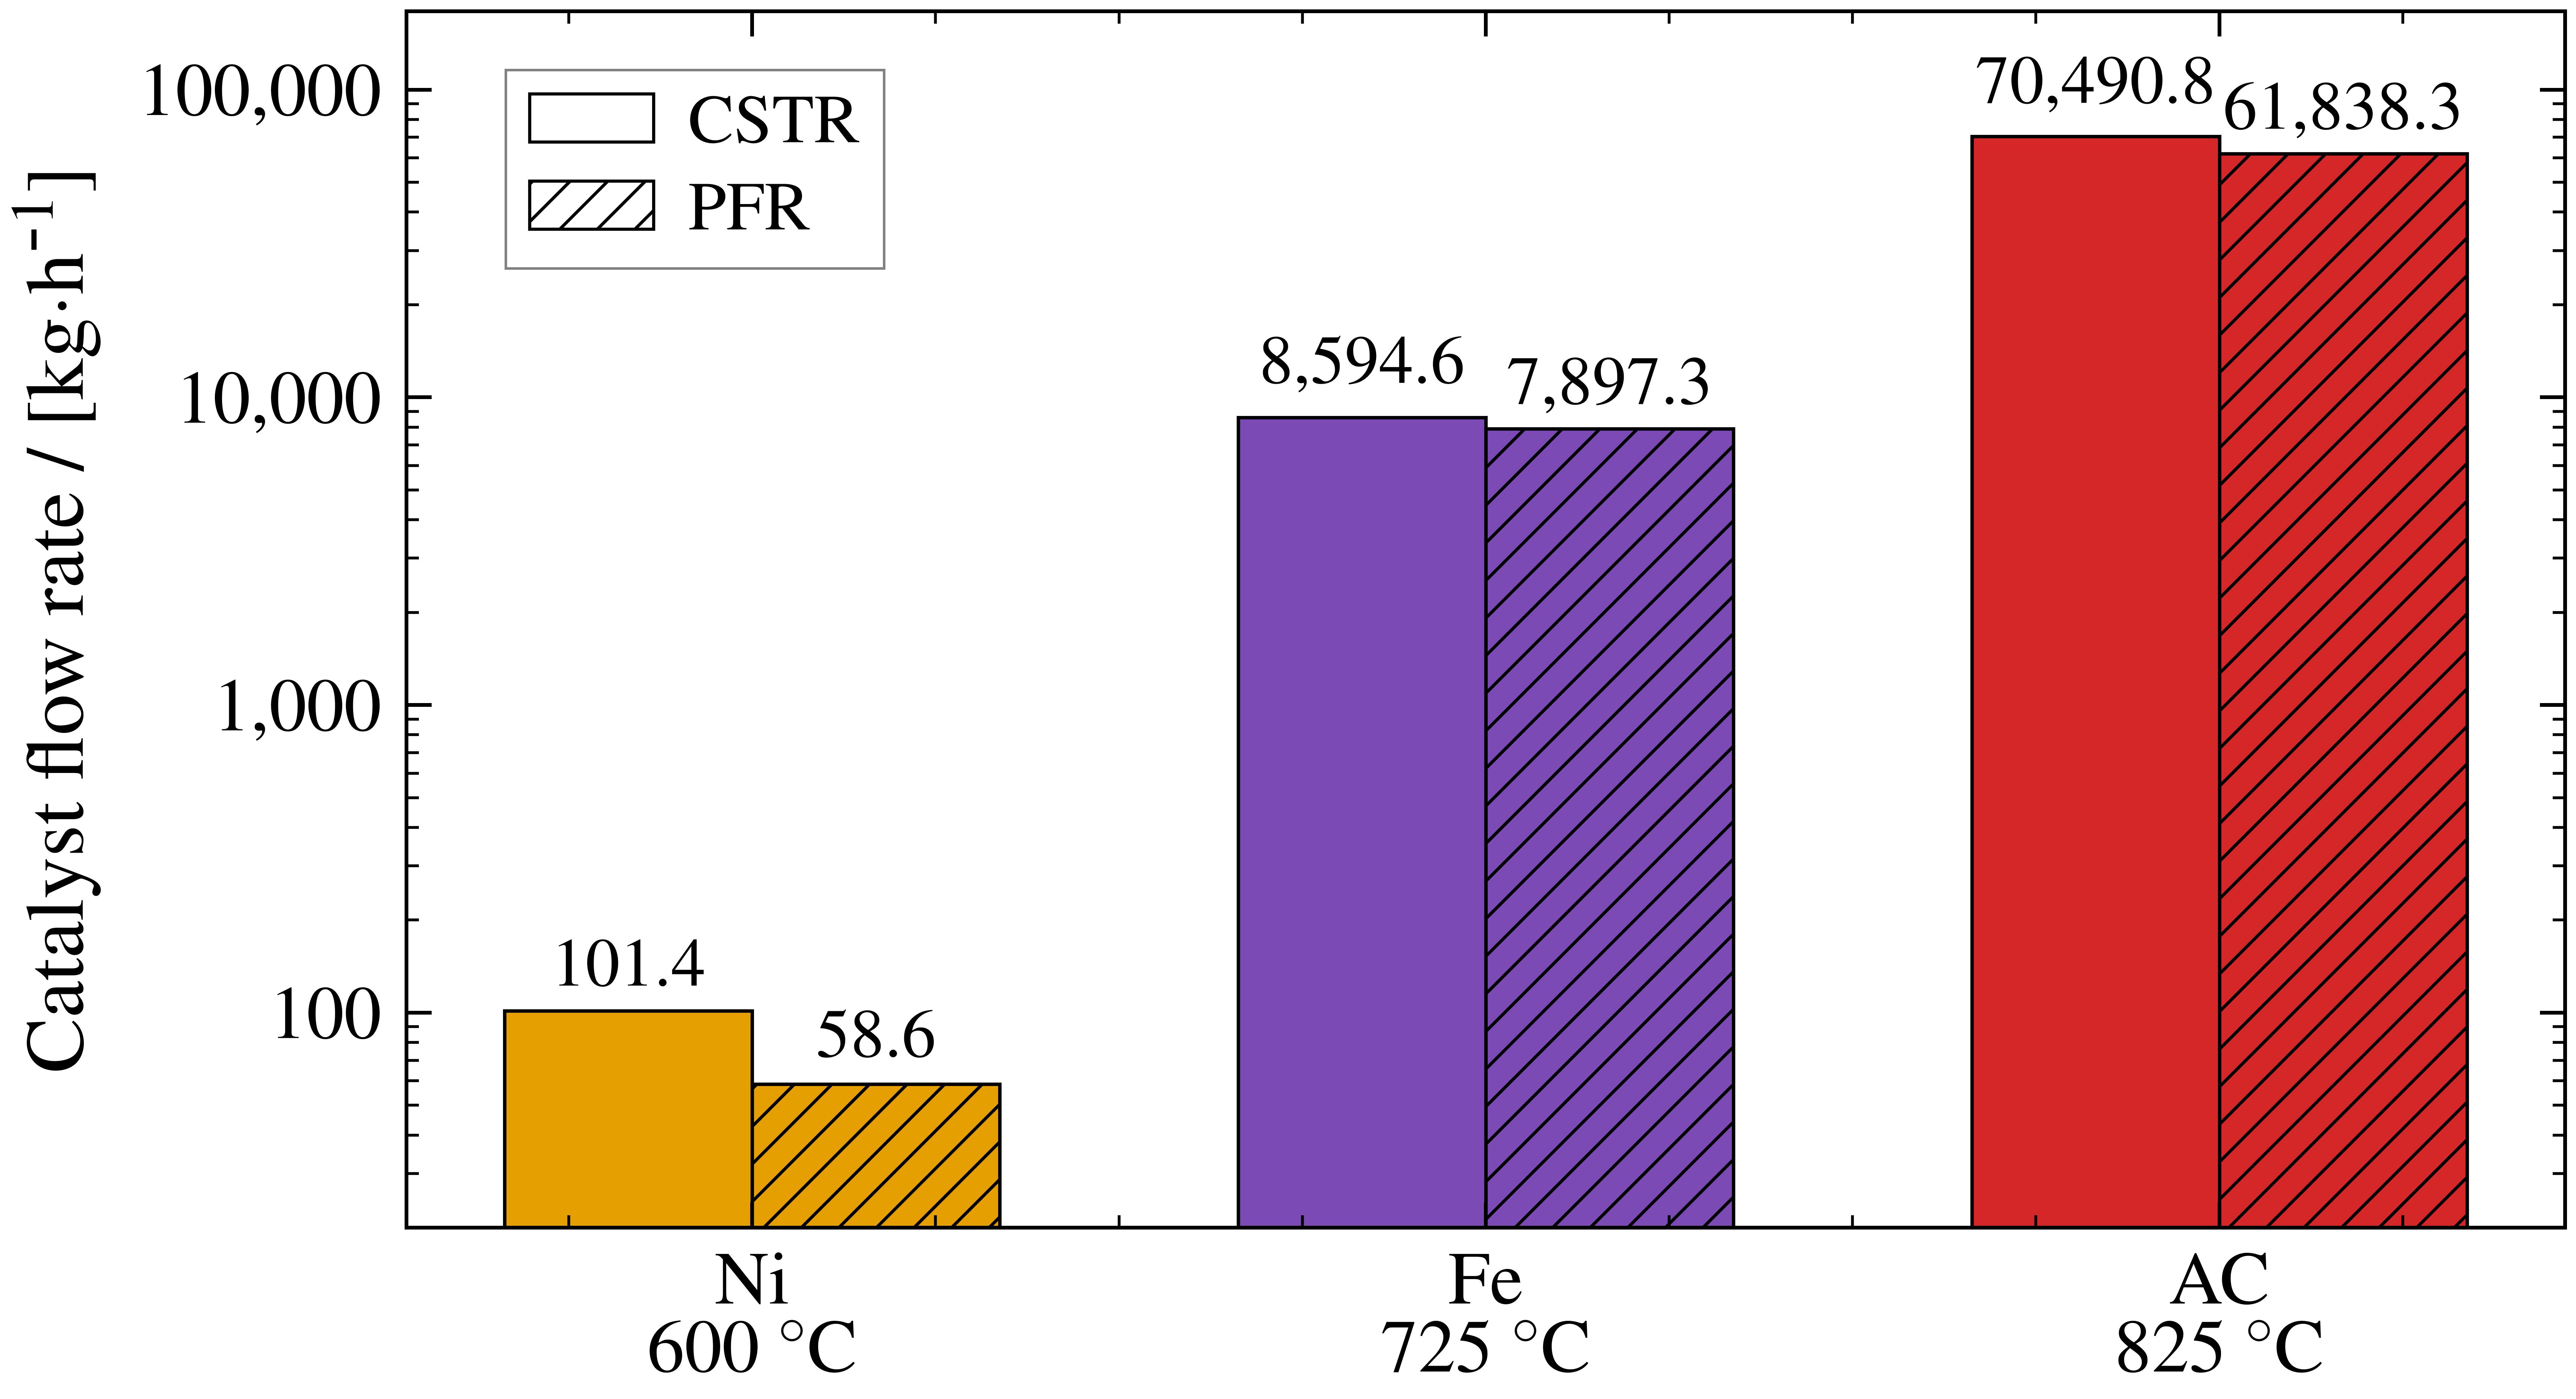

In [25]:
TICK_FONT = 24.0
AXIS_LABEL_FONT = 26.5
LEGEND_FONT = 22.0
VALUE_FONT = 22.0

y_min, y_max = 20, 180_000
bar_width = 0.54
x = np.arange(len(names)) * 1.60

# Multiplicative offset of each value label above its bar (Ni, Fe, AC)
label_offsets = {"CSTR": [1.08, 1.16, 1.15], "PFR": [1.10, 1.08, 1.08]}
bar_shift = {"CSTR": -bar_width / 2, "PFR": +bar_width / 2}
hatch = {"CSTR": None, "PFR": "//"}

fig, ax = plt.subplots(figsize=(11.2, 7.1))

for reactor in REACTORS:
    values = flow_rate[reactor].to_numpy()
    bars = ax.bar(x + bar_shift[reactor], values - y_min, bottom=y_min, width=bar_width,
                  color=colors, edgecolor="black", linewidth=1.1, hatch=hatch[reactor])
    annotate_bars(ax, bars, values, label_offsets[reactor], fontsize=VALUE_FONT,
                  fmt=lambda value: f"{value:,.1f}")

style_log_axis(ax, y_min, y_max, major_length=8, minor_length=4, major_width=1.2,
               minor_width=0.9, spine_width=1.2, label_size=TICK_FONT, pad=8)

ax.set_ylabel(r"Catalyst flow rate / [kg$\cdot$h$^{\mbox{-}1}$]",
              fontsize=AXIS_LABEL_FONT, labelpad=12)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=TICK_FONT)

legend_handles = [
    Patch(facecolor="white", edgecolor="black", linewidth=1.0, hatch=hatch[r], label=r)
    for r in REACTORS
]
legend = ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(0.03, 0.98),
                   frameon=True, fancybox=False, framealpha=1.0, facecolor="white",
                   edgecolor="0.50", fontsize=LEGEND_FONT, borderpad=0.35,
                   handlelength=1.8, handletextpad=0.5, labelspacing=0.35)
legend.get_frame().set_linewidth(0.8)

fig.subplots_adjust(left=0.13, right=0.985, bottom=0.20, top=0.96)
fig.savefig("catalyst_flow_rate_cstr_vs_pfr.pdf", format="pdf")
plt.show()

## Figure 3: Combined figure, (a) inventory and (b) flow rate

Both panels in one double-column figure with the same font size, tick style and x-axis. Flow rates are rounded to whole kg/h, because the decimals were spurious precision and made the AC labels collide.

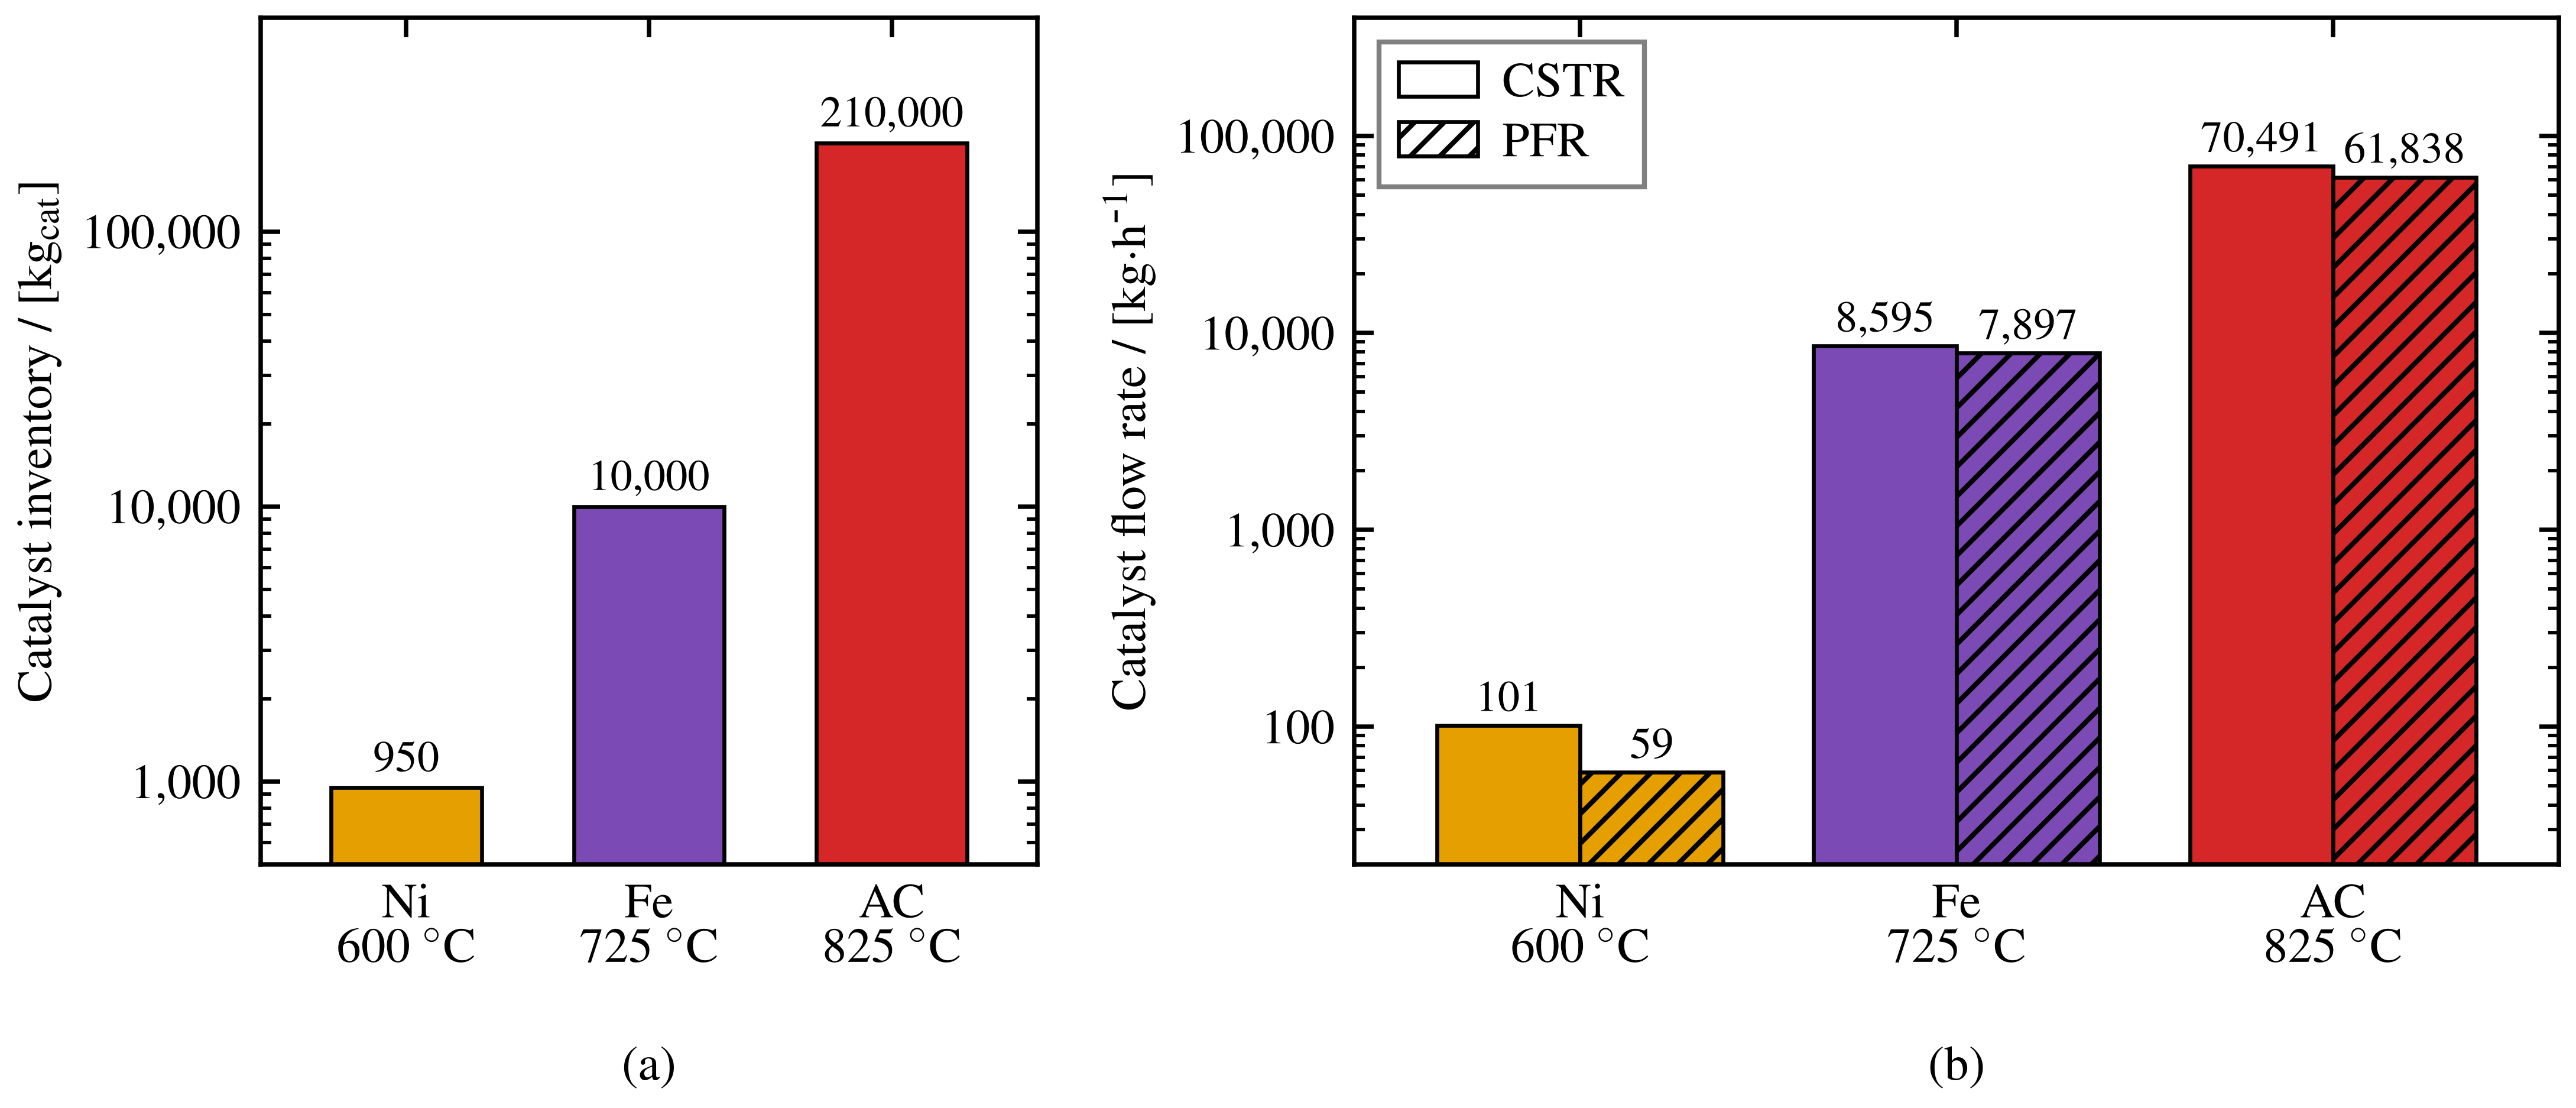

In [26]:
FONT = 10.0          # one font size for ticks, labels and legend in both panels
VALUE_FONT = 9.0     # bar value labels

fig, (ax_a, ax_b) = plt.subplots(
    1, 2, figsize=(7.2, 3.1), gridspec_kw={"width_ratios": [1.0, 1.55], "wspace": 0.32}
)

tick_style = dict(major_length=4.0, minor_length=2.2, major_width=0.9, minor_width=0.7,
                  spine_width=0.9, label_size=FONT, pad=4)

# (a) Catalyst inventory
x_a = np.arange(len(names))
bars = ax_a.bar(x_a, inventory - 500, bottom=500, width=0.62,
                color=colors, edgecolor="black", linewidth=0.8, zorder=2)
style_log_axis(ax_a, 500, 600_000, **tick_style)
annotate_bars(ax_a, bars, inventory, [1.06] * len(names), fontsize=VALUE_FONT, fmt=thousands)
ax_a.set_ylabel(r"Catalyst inventory / [kg$_{\mathrm{cat}}$]", fontsize=FONT)
ax_a.set_xlim(-0.6, len(names) - 0.4)

# (b) Catalyst flow rate, CSTR (solid) vs PFR (hatched)
bar_width = 0.38
x_b = np.arange(len(names))
shift = {"CSTR": -bar_width / 2, "PFR": +bar_width / 2}
hatch = {"CSTR": None, "PFR": "////"}

for reactor in REACTORS:
    values = flow_rate[reactor].to_numpy()
    bars = ax_b.bar(x_b + shift[reactor], values - 20, bottom=20, width=bar_width,
                    color=colors, edgecolor="black", linewidth=0.8, hatch=hatch[reactor], zorder=2)
    annotate_bars(ax_b, bars, values, [1.06] * len(names), fontsize=VALUE_FONT,
                  fmt=lambda value: f"{value:,.0f}")

style_log_axis(ax_b, 20, 400_000, **tick_style)
ax_b.set_ylabel(r"Catalyst flow rate / [kg$\cdot$h$^{\mbox{-}1}$]", fontsize=FONT)
ax_b.set_xlim(-0.6, len(names) - 0.4)
ax_b.legend(
    handles=[Patch(facecolor="white", edgecolor="black", linewidth=0.8, hatch=hatch[r], label=r)
             for r in REACTORS],
    loc="upper left", frameon=True, fancybox=False, framealpha=1.0, edgecolor="0.5",
    fontsize=FONT, handlelength=1.6, handletextpad=0.5, borderpad=0.4, labelspacing=0.3,
)

# Shared x-axis treatment and panel labels
for ax, panel in [(ax_a, "(a)"), (ax_b, "(b)")]:
    ax.set_xticks(np.arange(len(names)))
    ax.set_xticklabels(x_labels, fontsize=FONT)
    ax.tick_params(axis="x", which="minor", top=False, bottom=False)
    ax.text(0.5, -0.215, panel, transform=ax.transAxes, ha="center", va="top", fontsize=FONT)

fig.subplots_adjust(left=0.09, right=0.99, bottom=0.20, top=0.97)
fig.savefig("catalyst_amount_and_flow_rate.pdf", format="pdf")
plt.show()

## Figure 4: Inventory vs flow rate

Each catalyst is one point per reactor type (CSTR filled, PFR open). The label gives the catalyst residence time, $\tau = m_\mathrm{cat} / \dot m_\mathrm{cat}$, for CSTR and PFR.

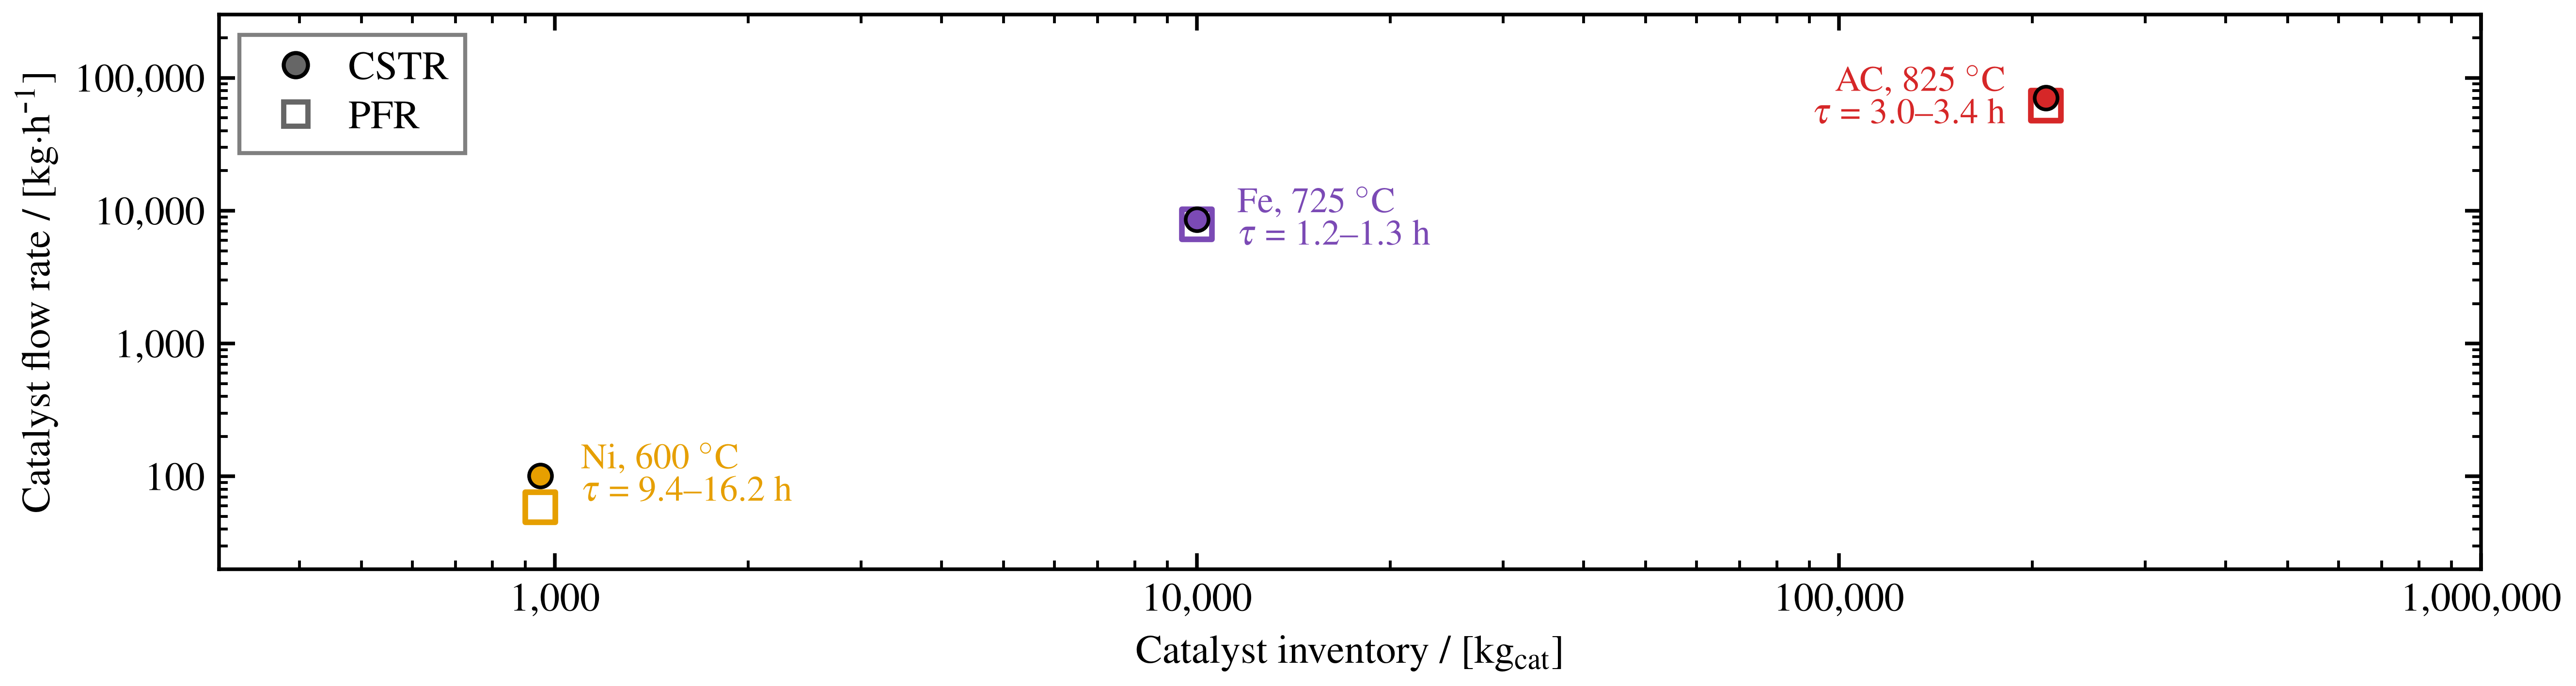

In [33]:
FONT = 10.0

fig, ax = plt.subplots(figsize=(9, 2.5))

marker = {"CSTR": "o", "PFR": "s"}
for name, color, m_cat in zip(names, colors, inventory):
    for reactor in REACTORS:
        is_cstr = reactor == "CSTR"  # CSTR: smaller filled circle drawn on top of the PFR square
        ax.scatter(m_cat, flow_rate.loc[name, reactor], s=32 if is_cstr else 55,
                   marker=marker[reactor], facecolor=color if is_cstr else "white",
                   edgecolor="black" if is_cstr else color, linewidth=0.9 if is_cstr else 1.4,
                   zorder=4 if is_cstr else 3)

    tau = m_cat / flow_rate.loc[name]  # catalyst residence time [h]
    left = name == "AC"  # keep the right-most label inside the axes
    ax.annotate(
        rf"{name}, {CATALYSTS[name]['temperature']} $^\circ$C" "\n"
        rf"$\tau$ = {tau['CSTR']:.1f}--{tau['PFR']:.1f} h",
        xy=(m_cat, flow_rate.loc[name, "CSTR"]), xytext=(-10 if left else 10, 0),
        textcoords="offset points", ha="right" if left else "left", va="center",
        fontsize=FONT - 1, color=color, linespacing=1.3,
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(3e2, 1e6)
ax.set_ylim(2e1, 3e5)
ax.xaxis.set_major_formatter(FuncFormatter(thousands))
ax.yaxis.set_major_formatter(FuncFormatter(thousands))
ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FONT)
ax.tick_params(which="major", length=4.0, width=0.9)
ax.tick_params(which="minor", length=2.2, width=0.7)
for spine in ax.spines.values():
    spine.set_linewidth(0.9)

ax.set_xlabel(r"Catalyst inventory / [kg$_{\mathrm{cat}}$]", fontsize=FONT)
ax.set_ylabel(r"Catalyst flow rate / [kg$\cdot$h$^{\mbox{-}1}$]", fontsize=FONT)

ax.legend(
    handles=[
        plt.Line2D([], [], marker="o", linestyle="", markersize=6, markerfacecolor="0.4",
                   markeredgecolor="black", label="CSTR"),
        plt.Line2D([], [], marker="s", linestyle="", markersize=6, markerfacecolor="white",
                   markeredgecolor="0.4", markeredgewidth=1.3, label="PFR"),
    ],
    loc="upper left", frameon=True, fancybox=False, framealpha=1.0, edgecolor="0.5",
    fontsize=FONT, handletextpad=0.3, borderpad=0.4, labelspacing=0.3,
)

fig.tight_layout()
fig.savefig("catalyst_inventory_vs_flow_rate.pdf", format="pdf")
plt.show()